In [39]:
# ==============================================================================
# 1. Environment Setup & Core Dependencies
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt
import pickle
import tensorflow as tf
from tensorflow.keras import layers, models


In [40]:
# ==============================================================================
# 2. Ingest CIFAR-10 Training Batches
# ==============================================================================
# The CIFAR-10 training set is partitioned across 5 binary batches (10,000 images each).
# Unpickle each batch using byte encoding.
with open("cifar-10-batches-py/data_batch_1", "rb") as f:
    batch1 = pickle.load(f, encoding="bytes")

with open("cifar-10-batches-py/data_batch_2", "rb") as f:
    batch2 = pickle.load(f, encoding="bytes")

with open("cifar-10-batches-py/data_batch_3", "rb") as f:
    batch3 = pickle.load(f, encoding="bytes")

with open("cifar-10-batches-py/data_batch_4", "rb") as f:
    batch4 = pickle.load(f, encoding="bytes")

with open("cifar-10-batches-py/data_batch_5", "rb") as f:
    batch5 = pickle.load(f, encoding="bytes")


In [41]:
# ==============================================================================
# 3. Aggregate Training Features and Ground-Truth Labels
# ==============================================================================
# Concatenate all 5 batches into unified arrays (50,000 total training samples).
# - X_train: Raw flattened image arrays (50,000 x 3072 features)
# - y_train: Target class labels (0 to 9)
X_train = np.concatenate([
    batch1[b"data"],
    batch2[b"data"],
    batch3[b"data"],
    batch4[b"data"],
    batch5[b"data"]
])

y_train = np.concatenate([
    batch1[b"labels"],
    batch2[b"labels"],
    batch3[b"labels"],
    batch4[b"labels"],
    batch5[b"labels"]
])


In [42]:
# Verify initial dimensions of the aggregated training data
print("Raw X_train shape:", X_train.shape)  # Expected: (50000, 3072)
print("Raw y_train shape:", y_train.shape)  # Expected: (50000,)


(50000, 3072)
(50000,)


In [43]:
# ==============================================================================
# 4. Ingest CIFAR-10 Test Batch
# ==============================================================================
# Load the official test partition containing 10,000 unseen images for model evaluation.
with open("cifar-10-batches-py/test_batch", "rb") as f:
    test = pickle.load(f, encoding="bytes")

X_test = test[b"data"]
y_test = np.array(test[b"labels"])


In [44]:
# ==============================================================================
# 5. Reshape and Transpose Tensor Geometry
# ==============================================================================
# CIFAR-10 stores pixels in planar order (3 channels x 32 rows x 32 columns).
# 1. Reshape from (N, 3072) to (N, 3, 32, 32) [channels_first / NCHW format].
# 2. Transpose axes to (N, 32, 32, 3) [channels_last / NHWC format], which is the
#    standard spatial convention expected by TensorFlow/Keras 2D convolution layers.
X_train = X_train.reshape(-1, 3, 32, 32)
X_train = X_train.transpose(0, 2, 3, 1)

X_test = X_test.reshape(-1, 3, 32, 32)
X_test = X_test.transpose(0, 2, 3, 1)


In [45]:
# ==============================================================================
# 6. Feature Normalization (Min-Max Rescaling)
# ==============================================================================
# Convert uint8 integer pixel values [0, 255] to float32 normalized intensities [0.0, 1.0].
# Scaling promotes numerical stability and accelerates gradient descent convergence.
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0


In [46]:
# Confirm processed tensor dimensions: (num_samples, height, width, channels)
print("Processed X_train shape:", X_train.shape)  # Expected: (50000, 32, 32, 3)
print("Processed X_test shape: ", X_test.shape)   # Expected: (10000, 32, 32, 3)


(50000, 32, 32, 3)
(10000, 32, 32, 3)


In [116]:
# ==============================================================================
# 7. Deep Convolutional Neural Network (CNN) Architecture
# ==============================================================================
# Architecture overview:
# - Input: Explicit 32x32x3 tensor specification (Keras 3 / modern TF standard).
# - Conv2D Blocks: 3 hierarchical feature extractor stages (32 -> 64 -> 128 filters).
#   Uses 3x3 kernels, ReLU activation, and 'same' padding to retain spatial dimensions.
# - MaxPooling2D: (2x2) window downsampling by half after each conv block for spatial invariance.
# - Flatten: Unrolls feature maps into a 1D representation for dense classification.
# - Dense (256): High-capacity fully connected representation layer with ReLU activation.
# - Dropout (0.5): Regularization dropping 50% of hidden units to prevent co-adaptation/overfitting.
# - Dense (10): Output layer with Softmax activation yielding probabilities across 10 classes.
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    # Feature Extractor - Stage 1 (Low-level features: edges, textures)
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Feature Extractor - Stage 2 (Mid-level features: corners, complex patterns)
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Feature Extractor - Stage 3 (High-level abstract features: object parts)
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Dense Classification Head
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax")
])

# Print architectural summary with layer dimensions and trainable parameters
model.summary()


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_24 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_22 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 620,362 (2.37 MB)

 Trainable params: 620,362 (2.37 MB)

 Non-trainable params: 0 (0.00 B)

In [117]:
# ==============================================================================
# 8. Model Compilation & Optimization Configuration
# ==============================================================================
# - Optimizer: Adam with adaptive learning rates for efficient stochastic optimization.
# - Loss: Sparse Categorical Crossentropy (appropriate for mutually exclusive integer labels).
# - Metric: Classification accuracy tracked across training and validation splits.
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


In [118]:
# ==============================================================================
# 9. Model Training with Holdout Validation
# ==============================================================================
# - epochs: 12 complete passes over the training partition.
# - batch_size: 64 samples per gradient update step.
# - validation_split: 10% (5,000 samples) reserved for real-time validation monitoring.
history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.1
)


Epoch 1/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.4205 - loss: 1.5819 - val_accuracy: 0.5324 - val_loss: 1.2765
Epoch 2/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.5775 - loss: 1.1903 - val_accuracy: 0.5892 - val_loss: 1.1726
Epoch 3/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.6466 - loss: 1.0085 - val_accuracy: 0.6954 - val_loss: 0.8585
Epoch 4/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.6916 - loss: 0.8921 - val_accuracy: 0.7084 - val_loss: 0.8524
Epoch 5/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.7215 - loss: 0.8041 - val_accuracy: 0.7140 - val_loss: 0.8215
Epoch 6/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.7467 - loss: 0.7214 - val_accuracy: 0.7480 - val_loss: 0.7418
Epoch 7/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.7697 - loss: 0.6613 - val_accuracy: 0.7512 - val_loss: 0.7295
Epoch 8/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.7906 - loss: 0.6020 - 

In [119]:
# ==============================================================================
# 10. Quantitative Generalization Evaluation on Test Partition
# ==============================================================================
# Evaluate cross-entropy loss and top-1 accuracy on 10,000 unseen test samples.
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7584 - loss: 0.8682
Test Loss:     0.8682
Test Accuracy: 75.84%


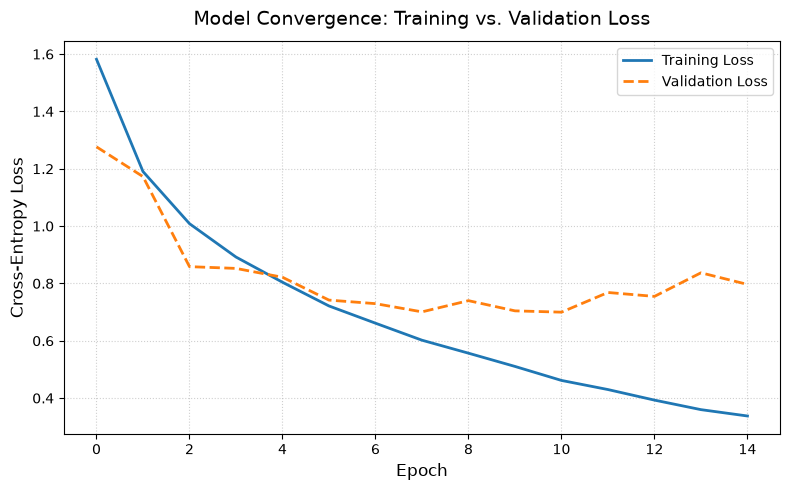

In [120]:
# ==============================================================================
# 11. Learning Dynamics Visualization (Loss Trajectory)
# ==============================================================================
# Compare training loss vs. validation loss across epochs to verify convergence
# and monitor potential overfitting/underfitting.
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss", linewidth=2)
plt.plot(history.history["val_loss"], label="Validation Loss", linewidth=2, linestyle="--")

plt.title("Model Convergence: Training vs. Validation Loss", fontsize=14, pad=12)
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Cross-Entropy Loss", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


In [121]:
# ==============================================================================
# 12. Inference & Single-Sample Prediction Pipeline
# ==============================================================================
# Canonical CIFAR-10 class label definitions
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# Select index of candidate sample from test partition
idx = 0

# Extract normalized input tensor and corresponding true label
image = X_test[idx]
actual_class = y_test[idx]

# Run forward inference: Add batch dimension (1, 32, 32, 3)
prediction = model.predict(
    np.expand_dims(image, axis=0),
    verbose=1
)[0]

# Determine class index corresponding to maximum output probability
predicted_class = np.argmax(prediction)

# Compute prediction confidence percentage
confidence = prediction[predicted_class] * 100

# Output prediction diagnostics
print(f"Predicted Class: {class_names[predicted_class]}")
print(f"Actual Class:    {class_names[actual_class]}")
print(f"Confidence:      {confidence:.2f}%")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
Predicted Class: cat
Actual Class:    cat
Confidence:      97.02%


In [122]:
# Get Top 5 classes
top5_indices = np.argsort(prediction)[-5:][::-1]

# Print Top 5 predictions
print("Top 5 Predictions:")
print("-" * 35)

for rank, class_index in enumerate(top5_indices, start=1):
    score = prediction[class_index] * 100
    
    print(
        "{}. {:<12} {:.2f}%".format(
            rank,
            class_names[class_index],
            score
        )
    )

Top 5 Predictions:
-----------------------------------
1. cat          97.02%
2. dog          2.61%
3. ship         0.26%
4. frog         0.10%
5. bird         0.00%


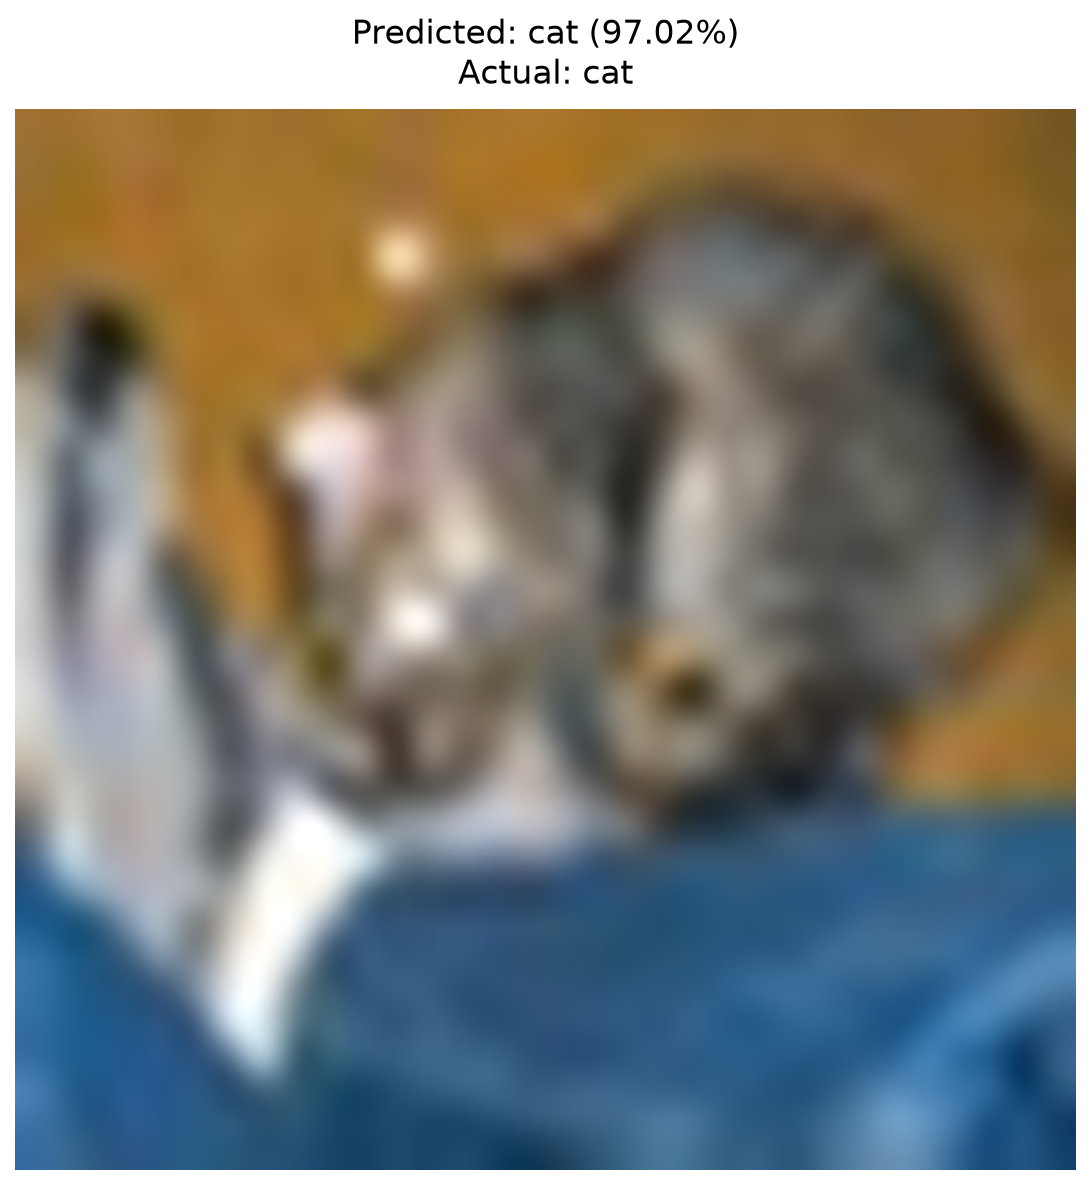

In [123]:
# ==============================================================================
# 13. Qualitative Sample Visualization (High-Resolution Rendering)
# ==============================================================================
# Denormalize, upscale using Lanczos resampling, and render the test sample
# with detailed prediction and ground-truth metadata.
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# Rescale normalized float32 intensities [0, 1] back to uint8 [0, 255]
img = Image.fromarray((image * 255).astype(np.uint8))

# Upscale from 32x32 to 720x720 using high-fidelity Lanczos interpolation
img = img.resize((720, 720), Image.Resampling.LANCZOS)

# Convert PIL image back to NumPy array for Matplotlib rendering
img = np.array(img)

# Display image with prediction overlay
plt.figure(figsize=(8, 8), dpi=150)
plt.imshow(img)

plt.title(
    f"Predicted: {class_names[predicted_class]} ({confidence:.2f}%)\nActual: {class_names[actual_class]}",
    fontsize=16,
    pad=12
)

plt.axis("off")
plt.tight_layout()
plt.show()


In [124]:
model.save("cnn_model.keras")